# Suggested support for at-risk students (ticket 216, SCRUM-188)

**Question.** Given why the model flags a student, which support types fit best, and what do similar past students show? **Method.**
- Each support type (tutoring, peer tutoring, mentoring, weekly check-ins, financial aid referral) is scored from the activity, assessment and study-load inputs that raise the student's risk score.
- Context comes from the 50 most similar students in the training presentations, from the same module.

**Rules.**
- OULAD records no interventions, so nothing here says a support type works.
- Background factors never drive a suggestion.
- The model and threshold are PROVISIONAL (team model from tickets 212 and 217, decision threshold from ticket 214, all pending).
- Outputs are aggregates or a synthetic student only.

Load the provisional model and its threshold, and build the pool of similar students from the training presentations.

In [1]:
import collections
import textwrap

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sar.config import MODELS_DIR, PROCESSED_DIR, RANDOM_SEED
from sar.data.split import TEST_PRESENTATION, make_split
from sar.explain.chart import short_label
from sar.explain.shap_explain import explain_student, make_explainer
from sar.models.forest import load_model
from sar.recommend.interventions import FEATURE_TO_INTERVENTIONS, INTERVENTIONS, label
from sar.recommend.neighbours import NeighbourPool
from sar.recommend.recommender import driver_scores, recommend
from sar.viz import plots

%matplotlib inline
model, meta = load_model(MODELS_DIR / "forest_provisional.json")
features, threshold = meta["features"], meta["threshold"]["threshold"]
train, val = make_split(pd.read_csv(PROCESSED_DIR / "day30_feature_matrix.csv"))
explainer = make_explainer(model)
pool = NeighbourPool(train)
print(f"PROVISIONAL model, threshold {threshold:.3f} | pool: {len(pool.data):,} students from "
      f"{', '.join(pool.presentations)} | k = {pool.k} | smallest module in the pool: "
      f"{train['code_module'].value_counts().min():,} students")

PROVISIONAL model, threshold 0.404 | pool: 16,915 students from 2013B, 2013J, 2014B | k = 50 | smallest module in the pool: 339 students


Which risk drivers point to which support type, and with what weight (an editable assumption, not learned from data).

In [2]:
mapping = pd.DataFrame(FEATURE_TO_INTERVENTIONS).T.fillna(0).reindex(columns=list(INTERVENTIONS))
mapping.index = [short_label(f) for f in mapping.index]
mapping.columns = [label(c) for c in mapping.columns]
mapping.replace(0, "").astype(str).replace("0.0", "")

,Tutoring,Peer tutoring,Mentoring,Weekly check-ins,Financial aid referral
Average score,0.6,0.4,,,
Weighted average score,0.6,0.4,,,
Change in score,0.6,0.4,,,
Assessments submitted,0.5,,,0.5,
Assessments missed,0.5,,,0.5,
Late submissions,,,0.4,0.6,
Average submission delay,,,0.4,0.6,
Total clicks,,0.4,,0.6,
Active days,,0.4,,0.6,
Clicks per active day,,0.4,,0.6,


Suggestions and similar-student context for a random sample of 300 validation students (used by the next three cells).

In [3]:
sample = val.sample(300, random_state=RANDOM_SEED)
records = []
for i in range(len(sample)):
    row = sample.iloc[[i]]
    expl = explain_student(model, row[features], threshold, explainer)
    rec = recommend(expl, row, pool)
    records.append({
        "flagged": bool(expl.flagged),
        "neighbour_at_risk_share": rec.neighbours.at_risk_share,
        "same_module": rec.neighbours.same_module,
        "suggestions": [s.label for s in rec.suggestions],
        "evidence_shown": sum("Too few" not in s.evidence for s in rec.suggestions),
    })
runs = pd.DataFrame(records)
print(f"students: {len(runs)} | flagged: {runs['flagged'].sum()} | "
      f"neighbours from the same module: {runs['same_module'].mean():.0%}")

students: 300 | flagged: 165 | neighbours from the same module: 100%


How often each support type is suggested first, and how often it is in the top three, for the flagged students.

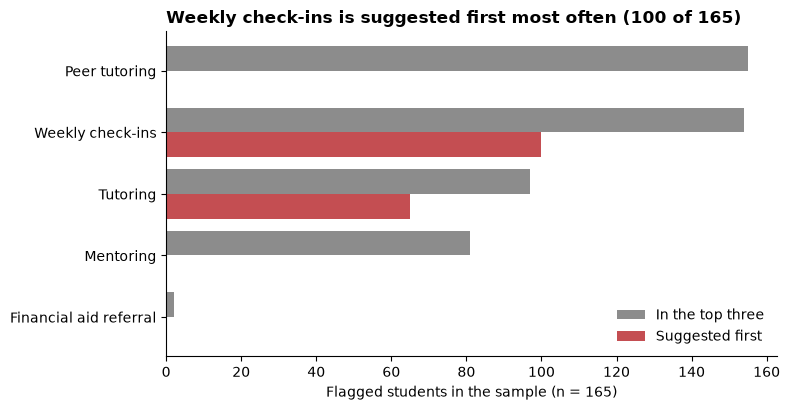

In [4]:
flagged = runs[runs["flagged"]]
first = collections.Counter(s[0] for s in flagged["suggestions"] if s)
top3 = collections.Counter(x for s in flagged["suggestions"] for x in s)
order = [label(k) for k in INTERVENTIONS]
counts = pd.DataFrame({"Suggested first": [first.get(k, 0) for k in order],
                       "In the top three": [top3.get(k, 0) for k in order]}, index=order).sort_values("In the top three")
fig, ax = plt.subplots(figsize=(8, 4.2))
y = np.arange(len(counts))
ax.barh(y + 0.2, counts["In the top three"], height=0.4, color=plots.NEUTRAL, label="In the top three")
ax.barh(y - 0.2, counts["Suggested first"], height=0.4, color=plots.AT_RISK, label="Suggested first")
ax.set_yticks(y, counts.index)
ax.set_xlabel(f"Flagged students in the sample (n = {len(flagged)})")
ax.legend(frameon=False, loc="lower right")
ax.spines[["top", "right"]].set_visible(False)
lead = counts["Suggested first"].idxmax()
ax.set_title(f"{lead} is suggested first most often ({counts.loc[lead, 'Suggested first']} of {len(flagged)})",
             loc="left", fontsize=12, fontweight="bold")
fig.tight_layout()

Whether outcomes of similar past students agree with the model: the share of each student's 50 neighbours who ended At Risk.

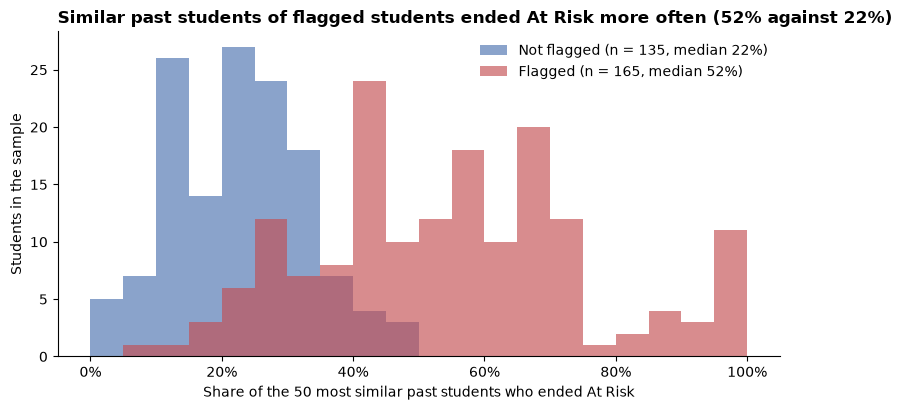

In [5]:
fig, ax = plt.subplots(figsize=(8, 4.2))
bins = np.linspace(0, 1, 21)
for is_flagged, colour, name in [(False, plots.ON_TRACK, "Not flagged"), (True, plots.AT_RISK, "Flagged")]:
    part = runs.loc[runs["flagged"] == is_flagged, "neighbour_at_risk_share"]
    ax.hist(part, bins=bins, alpha=0.65, color=colour, label=f"{name} (n = {len(part)}, median {part.median():.0%})")
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1, decimals=0))
ax.set_xlabel("Share of the 50 most similar past students who ended At Risk")
ax.set_ylabel("Students in the sample")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
med = runs.groupby("flagged")["neighbour_at_risk_share"].median()
ax.set_title(f"Similar past students of flagged students ended At Risk more often ({med[True]:.0%} against {med[False]:.0%})",
             loc="left", fontsize=12, fontweight="bold")
fig.tight_layout()

How often a suggestion could show medians for both outcome groups (each group needs at least 10 similar students).

In [6]:
shown = int(flagged["evidence_shown"].sum())
total = int(flagged["suggestions"].map(len).sum())
pd.DataFrame({"Suggestions": [total], "With medians shown": [shown], "Too few in one group": [total - shown],
              "Share shown": [f"{shown / total:.0%}"]}, index=["Flagged students"])

,Suggestions,With medians shown,Too few in one group,Share shown
Flagged students,489,414,75,85%


A synthetic student built from the median values of at-risk training students (not a real student), and the full suggestion text.

In [7]:
at_risk_train = train.loc[train["at_risk"] == 1, features]
synthetic = pd.DataFrame([{c: at_risk_train[c].median() if at_risk_train[c].dtype.kind in "if" else at_risk_train[c].mode()[0]
                           for c in features}])
example = explain_student(model, synthetic, threshold, explainer)
example_rec = recommend(example, synthetic, pool)
for line in example_rec.text().splitlines():
    print(textwrap.fill(line, 100, subsequent_indent="   "))

The 50 most similar students from earlier presentations (2013B, 2013J, 2014B; module FFF): 24 ended
   At Risk (48%) and 26 On Track.
1. Weekly check-ins: linked to submitting on the due date on average and a longest run of 9 days
   without activity. Similar students had the same median in both groups (submitting 1 day early on
   average; On Track n = 26, At Risk n = 24), so this driver does not separate them here.
2. Mentoring: linked to registered 53 days before the start and submitting on the due date on
   average. Medians among similar students: On Track (n = 26) registered 44 days before the start;
   At Risk (n = 24) registered 43 days before the start.
3. Peer tutoring: linked to 10 active days by Day 30 and an average score of 70. Medians among
   similar students: On Track (n = 26) 13 active days by Day 30; At Risk (n = 24) 12 active days by
   Day 30.
Suggestions match the model's risk drivers to support types. Figures for similar past students show
   patterns, not the ef

How each support type scored for the synthetic student; the top three are the suggestions.

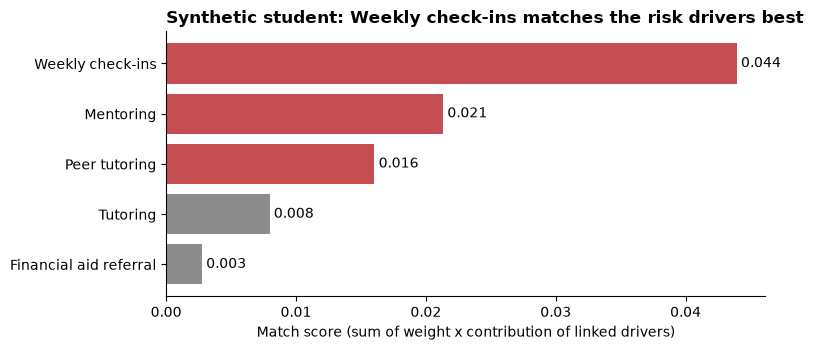

In [8]:
match = driver_scores(example).groupby("intervention")["score"].sum().reindex(list(INTERVENTIONS), fill_value=0)
match = match.sort_values()
chosen = {s.intervention for s in example_rec.suggestions}
fig, ax = plt.subplots(figsize=(8, 3.6))
bars = ax.barh([label(k) for k in match.index], match.values,
               color=[plots.AT_RISK if k in chosen else plots.NEUTRAL for k in match.index])
ax.bar_label(bars, labels=[f"{v:.3f}" for v in match.values], padding=3)
ax.set_xlabel("Match score (sum of weight x contribution of linked drivers)")
ax.spines[["top", "right"]].set_visible(False)
ax.set_title(f"Synthetic student: {label(match.index[-1])} matches the risk drivers best", loc="left",
             fontsize=12, fontweight="bold")
fig.tight_layout()

## Limits

- **Associations only.** OULAD records no interventions. The neighbour figures describe what similar past students looked like, not what any support would change.
- **The mapping is an assumption.** Which drivers point to which support type is a starting point for staff to review. It is not learned from data.
  - Weekly check-ins and peer tutoring come up often, because many activity inputs map to them.
  - Financial aid referral is rare, because it is matched only from study load and registration timing, never from the deprivation band.
- **Background factors never drive a suggestion, but they still enter indirectly.** The model uses them, and in tree models an input can change how much the other inputs contribute.
- **Small groups are hidden.** When one outcome group among the 50 neighbours has fewer than 10 students, no medians are shown.
- **The model and threshold are PROVISIONAL** until the team model (tickets 212 and 217) and the decision threshold (ticket 214) are in the repo. The neighbour pool uses the training presentations only, so 2014J outcomes never reach a suggestion.
- **No 3D view.** None adds meaning here: suggestions are rankings over five categories, and a neighbour-space plot would need individual students.